# 11 - Attack diagnostics: is the limit the objective or the budget?

Notebook 09 established the main result: the attack **changes** the explanation (gradient
map correlation 0.236, three quarters of the hot-spots relocated) while leaving the
decision and the score untouched - but the relocated map stays **almost as faithful**
(deletion AUC 0.180 -> 0.201 against a random floor of 0.370, only ~11% of the available
distance).

The conclusion attributes that to an **objective/metric mismatch**: the attack minimises
correlation, so it relocates saliency onto *other genuinely informative* pixels rather than
onto uninformative ones. Two parts of that argument are currently asserted rather than
demonstrated, and one of them contains a visible tension.

| Claim | Evidence we have | Evidence we lack |
|---|---|---|
| The limit is the **objective**, not the perturbation budget | - | **What happens when the band is loosened.** 49.9% of pairs were shrunk below 3/255, which argues the *budget* is binding |
| Saliency relocated onto other **informative** pixels (redundancy) | per-pair corr(map movement, faithfulness lost) = -0.347 | **Where the saliency mass actually went** |

This notebook closes both, and tests the one alternative objective that could change the
headline. Three parts, all at subset scale, roughly 20 minutes of GPU in total.

* **Part A - loosen the score band.** Sweep `SIM_TOL` and watch the deletion AUC. If it
  stays flat the limit is the objective; if it climbs the limit is the budget.
* **Part B - where did the saliency go?** Measure the off-face mass, the centre-of-mass
  shift, and whether the new hot-spots are still inside the face. This is the direct test
  of the redundancy explanation.
* **Part C - attack faithfulness directly.** Replace the correlation objective with an
  off-face mass objective, so the attack is *rewarded* for pointing at pixels that carry no
  identity. Subset first, with an explicit decision rule for whether a full run is worth it.

Part D combines the three into a verdict, stated in the terms the write-up needs.

Everything else - the two-sided score band, the hard projection, the evaluation - is
identical to notebook 09, so every number here is directly comparable to it.


## CONFIG - edit only this cell


In [23]:
import torch

# =================================================================
# PATHS - update to match your Kaggle dataset / model slugs
# =================================================================
IMAGES_DIR   = "/kaggle/input/datasets/xitij27/hcml-lfw-dataset/imgs"
WEIGHTS_PATH = "/kaggle/input/models/xitij27/elastic-face-arc/pytorch/default/1/ElasticFaceArc.pth"
OUTPUT_DIR   = "/kaggle/working/"

# =================================================================
# DATASET LAYOUT  -  the fix for feedback point 1
# =================================================================
# The image directory holds 12,000 files (0.jpg .. 11999.jpg), i.e. 6,000
# pairs, NOT the 900 pairs used in notebooks 01-05.  Consecutive images form
# a pair (0,1), (2,3), ...  The pairs follow the standard LFW view-2 layout:
# 10 folds x 600 pairs, and each fold is 300 genuine pairs followed by 300
# imposter pairs.  Notebook 06 verifies this empirically before use.
N_IMAGES         = 12000
N_PAIRS          = N_IMAGES // 2      # 6000
PAIRS_PER_FOLD   = 600
GENUINE_PER_FOLD = 300
N_FOLDS          = N_PAIRS // PAIRS_PER_FOLD   # 10

# =================================================================
# PROBE / REFERENCE  -  the fix for feedback point 4
# =================================================================
# An attack may modify exactly ONE image of a pair: the "probe".  The other
# image, the "reference", is never touched.  PROBE_SIDE="random" picks the
# side with a seeded per-pair coin flip, so the attacked image is not
# systematically image 0 of every pair while the run stays reproducible.
PROBE_SIDE = "random"        # 0 | 1 | "random"
PROBE_SEED = 20260728

# =================================================================
# MODEL
# =================================================================
NUM_FEATURES = 512
IMG_SIZE     = 112

# =================================================================
# THIS NOTEBOOK
# =================================================================
DIAG_PAIRS   = 300       # accepted genuine pairs used by every part
ATTACK_BATCH = 16

# --- attack (identical to notebook 09 unless swept) -----------------------
EPSILON_255 = 4.0
STEPS_EXPL  = 40
ALPHA_FRAC  = 0.15
LAMBDA_PRED = 4.0
LAMBDA_EXPL = 1.0
SIM_TOL     = 0.05       # notebook 09's value; Part A sweeps around it
SHRINK_STEPS = 8

# --- Part A: the score-band sweep ----------------------------------------
SIM_TOL_SWEEP = [0.02, 0.05, 0.10, 0.20]

# --- Parts B and C: the off-face region ----------------------------------
# A border frame of the crop.  These images are tightly aligned 112x112 face
# crops, so the outer 22% on each side is hair, background and shoulders -
# it carries little or no identity evidence.
BORDER_FRAC = 0.22       # no longer used
ELLIPSE_A   = 46.0       # horizontal semi-axis, px
ELLIPSE_B   = 54.0       # vertical semi-axis, px

# --- Part C: full-run promotion ------------------------------------------
# If the subset result clears TARGET_DECISION_GOOD, re-run this notebook with
# TARGET_PAIRS = None to get the full-scale comparison against notebook 09.
TARGET_PAIRS         = None   # None = use DIAG_PAIRS; set to an int to override
TARGET_DECISION_GOOD = 0.30   # move >30% toward the random floor -> full run
TARGET_DECISION_POOR = 0.15   # move <15% -> report as a second negative result

# --- the random floor measured in notebook 07 (genuine pairs) ------------
RANDOM_DEL_AUC = 0.3698
RANDOM_INS_AUC = 0.4806

# --- explanation / evaluation --------------------------------------------
XSSAB_THR = 0.0
XFACE_GRID          = 14
XFACE_OCC_BATCH     = 196
XFACE_OCCLUDE_VALUE = 0.0
RANDOM_SALIENCY_SEED = 1234
INSDEL_STEPS      = 20
DELETE_VALUE      = 0.0
INSERT_BLUR_SIGMA = 8.0
TOPK_FRAC         = 0.10
CHECKPOINT_EVERY  = 100

# Must lie inside the diagnostic subset, which is the first DIAG_PAIRS accepted
# genuine pairs (pair indices 0-602 at DIAG_PAIRS=300).  Pair 3000 is genuine and
# accepted but falls outside that window, so it would be silently skipped.
VIZ_PAIRS = [0, 1, 200]

# =================================================================
# RUNTIME
# =================================================================
USE_AMP        = True     # fp16 autocast for EVALUATION forward passes only
                          # (never inside an attack loop - see notebook 08/09)
EMBED_BATCH    = 128      # batch size for plain embedding extraction
PRELOAD_IMAGES = True     # cache all 12,000 images in RAM (~450 MB)
N_GPUS         = None     # None = use every visible GPU.  Kaggle's "GPU T4 x2"
                          # exposes two; set to 1 to force single-GPU.

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Primary device : {DEVICE}")
for _i in range(torch.cuda.device_count()):
    _p = torch.cuda.get_device_properties(_i)
    print(f"  cuda:{_i} : {_p.name}  {_p.total_memory / 1e9:.1f} GB")

Primary device : cuda
  cuda:0 : Tesla T4  15.6 GB
  cuda:1 : Tesla T4  15.6 GB


## Imports


In [5]:
import os
import json
import math
import numpy as np
import cv2
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import pandas as pd
from contextlib import nullcontext
from tqdm.auto import tqdm
import warnings
warnings.filterwarnings("ignore")

np.random.seed(0)
torch.manual_seed(0)
if torch.cuda.is_available():
    torch.backends.cudnn.benchmark = True

## Backbone


In [6]:
def conv3x3(in_planes, out_planes, stride=1, groups=1, dilation=1):
    return nn.Conv2d(in_planes, out_planes, kernel_size=3, stride=stride,
                     padding=dilation, groups=groups, bias=False, dilation=dilation)

def conv1x1(in_planes, out_planes, stride=1):
    return nn.Conv2d(in_planes, out_planes, kernel_size=1, stride=stride, bias=False)


class IBasicBlock(nn.Module):
    expansion = 1
    def __init__(self, inplanes, planes, stride=1, downsample=None,
                 groups=1, base_width=64, dilation=1, use_se=False):
        super().__init__()
        self.bn1        = nn.BatchNorm2d(inplanes, eps=1e-05)
        self.conv1      = conv3x3(inplanes, planes)
        self.bn2        = nn.BatchNorm2d(planes, eps=1e-05)
        self.prelu      = nn.PReLU(planes)
        self.conv2      = conv3x3(planes, planes, stride)
        self.bn3        = nn.BatchNorm2d(planes, eps=1e-05)
        self.downsample = downsample
        self.stride     = stride

    def forward(self, x):
        identity = x
        out = self.bn1(x)
        out = self.conv1(out)
        out = self.bn2(out)
        out = self.prelu(out)
        out = self.conv2(out)
        out = self.bn3(out)
        if self.downsample is not None:
            identity = self.downsample(x)
        out += identity
        return out


class IResNet(nn.Module):
    fc_scale = 7 * 7
    def __init__(self, block, layers, dropout=0, num_features=512,
                 groups=1, width_per_group=64,
                 replace_stride_with_dilation=None):
        super().__init__()
        self.inplanes   = 64
        self.dilation   = 1
        if replace_stride_with_dilation is None:
            replace_stride_with_dilation = [False, False, False]
        self.groups     = groups
        self.base_width = width_per_group
        self.conv1      = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn1        = nn.BatchNorm2d(64, eps=1e-05)
        self.prelu      = nn.PReLU(64)
        self.layer1     = self._make_layer(block, 64,  layers[0], stride=2)
        self.layer2     = self._make_layer(block, 128, layers[1], stride=2,
                                           dilate=replace_stride_with_dilation[0])
        self.layer3     = self._make_layer(block, 256, layers[2], stride=2,
                                           dilate=replace_stride_with_dilation[1])
        self.layer4     = self._make_layer(block, 512, layers[3], stride=2,
                                           dilate=replace_stride_with_dilation[2])
        self.bn2        = nn.BatchNorm2d(512 * block.expansion, eps=1e-05)
        self.dropout    = nn.Dropout(p=dropout, inplace=True)
        self.fc         = nn.Linear(512 * block.expansion * self.fc_scale, num_features)
        self.features   = nn.BatchNorm1d(num_features, eps=1e-05)
        nn.init.constant_(self.features.weight, 1.0)
        self.features.weight.requires_grad = False
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.normal_(m.weight, 0, 0.1)
            elif isinstance(m, (nn.BatchNorm2d, nn.GroupNorm)):
                nn.init.constant_(m.weight, 1)
                nn.init.constant_(m.bias, 0)

    def _make_layer(self, block, planes, num_blocks, stride=1, dilate=False):
        downsample    = None
        prev_dilation = self.dilation
        if dilate:
            self.dilation *= stride
            stride = 1
        if stride != 1 or self.inplanes != planes * block.expansion:
            downsample = nn.Sequential(
                conv1x1(self.inplanes, planes * block.expansion, stride),
                nn.BatchNorm2d(planes * block.expansion, eps=1e-05),
            )
        layers = [block(self.inplanes, planes, stride, downsample,
                        self.groups, self.base_width, prev_dilation)]
        self.inplanes = planes * block.expansion
        for _ in range(1, num_blocks):
            layers.append(block(self.inplanes, planes, groups=self.groups,
                                base_width=self.base_width, dilation=self.dilation))
        return nn.Sequential(*layers)

    def forward(self, x):
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.prelu(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        x = self.bn2(x)
        x = torch.flatten(x, 1)
        x = self.dropout(x)
        x = self.fc(x)
        x = self.features(x)
        return x


def elastic_iresnet100(**kwargs):
    return IResNet(IBasicBlock, [3, 13, 30, 3], **kwargs)

## Data, multi-GPU, thresholds, plotting


In [7]:
# ---------------------------------------------------------------- images ---
def preprocess(img_rgb):
    """(H,W,3) uint8 RGB -> (3,H,W) float32 tensor in [-1, 1]."""
    x = ((img_rgb.astype(np.float32) / 255.0) - 0.5) / 0.5
    return torch.from_numpy(np.ascontiguousarray(x.transpose(2, 0, 1)))


IMAGE_CACHE = None

def _read_image(img_idx):
    path = os.path.join(IMAGES_DIR, f"{img_idx}.jpg")
    bgr = cv2.imread(path)
    if bgr is None:
        raise FileNotFoundError(path)
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)


def preload_images(n=N_IMAGES):
    """Hold every image in RAM so the long loops never re-decode a JPEG."""
    global IMAGE_CACHE
    cache = np.zeros((n, IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8)
    for i in tqdm(range(n), desc="Caching images", leave=False):
        cache[i] = _read_image(i)
    IMAGE_CACHE = cache
    print(f"Cached {n:,} images ({cache.nbytes / 1e6:.0f} MB)")


def image_rgb(img_idx):
    return IMAGE_CACHE[img_idx] if IMAGE_CACHE is not None else _read_image(img_idx)


def image_tensor(img_idx):
    return preprocess(image_rgb(img_idx))


def tensor_to_uint8(t):
    """(3,H,W) or (1,3,H,W) float tensor in [-1,1] -> (H,W,3) uint8."""
    x = t.detach().float().cpu().numpy()
    if x.ndim == 4:
        x = x[0]
    x = x.transpose(1, 2, 0)
    return np.clip((x * 0.5 + 0.5) * 255, 0, 255).astype(np.uint8)


# ------------------------------------------------------- pair bookkeeping ---
def _build_probe_sides():
    if PROBE_SIDE in (0, 1):
        return np.full(N_PAIRS, int(PROBE_SIDE), dtype=np.int64)
    if PROBE_SIDE != "random":
        raise ValueError(f"PROBE_SIDE must be 0, 1 or 'random', got {PROBE_SIDE!r}")
    return np.random.RandomState(PROBE_SEED).randint(0, 2, size=N_PAIRS)

PROBE_SIDES = _build_probe_sides()


def probe_reference(pair_idx):
    """(probe_img_idx, reference_img_idx) - always two DIFFERENT image files.

    The probe is the ONLY image any attack in this project is allowed to
    modify; the reference is passed through the model untouched.
    """
    i0, i1 = 2 * int(pair_idx), 2 * int(pair_idx) + 1
    probe, ref = (i0, i1) if PROBE_SIDES[pair_idx] == 0 else (i1, i0)
    assert probe != ref, "probe and reference must be two different images"
    return probe, ref


def is_genuine(pair_idx):
    """LFW view-2: every fold is 300 genuine pairs then 300 imposter pairs."""
    return (np.asarray(pair_idx) % PAIRS_PER_FOLD) < GENUINE_PER_FOLD


def fold_of(pair_idx):
    return np.asarray(pair_idx) // PAIRS_PER_FOLD


PAIR_IDX   = np.arange(N_PAIRS)
IS_GENUINE = is_genuine(PAIR_IDX)
FOLD       = fold_of(PAIR_IDX)
PROBE_IMG  = np.where(PROBE_SIDES == 0, 2 * PAIR_IDX, 2 * PAIR_IDX + 1)
REF_IMG    = np.where(PROBE_SIDES == 0, 2 * PAIR_IDX + 1, 2 * PAIR_IDX)


def load_pair_batch(pair_indices, device=None):
    """-> (probes, references), each (B,3,112,112) on DEVICE."""
    device = device or DEVICE
    probes = torch.stack([image_tensor(int(PROBE_IMG[i])) for i in pair_indices]).to(device)
    refs   = torch.stack([image_tensor(int(REF_IMG[i]))   for i in pair_indices]).to(device)
    return probes, refs


# ----------------------------------------------------------------- model ---
def amp_ctx(device=None):
    dev = DEVICE if device is None else device
    if USE_AMP and dev.type == "cuda":
        return torch.autocast(device_type="cuda", dtype=torch.float16)
    return nullcontext()


def load_model_on(dev):
    m = elastic_iresnet100(num_features=NUM_FEATURES)
    state = torch.load(WEIGHTS_PATH, map_location="cpu")
    if isinstance(state, dict) and "state_dict" in state:
        state = state["state_dict"]
    m.load_state_dict(state)
    m = m.to(dev).eval()
    # We only ever differentiate w.r.t. the INPUT image, never the weights.
    # Freezing the parameters keeps the second-order graphs in notebook 09
    # from also tracking weight gradients.
    for p in m.parameters():
        p.requires_grad_(False)
    return m


def load_model():
    return load_model_on(DEVICE)


@torch.no_grad()
def embed_batch(x):
    """(B,3,H,W) -> (B,D) L2-normalised embeddings (float32)."""
    with amp_ctx(x.device):
        e = current_model()(x)
    return F.normalize(e.float(), dim=1)


@torch.no_grad()
def embed_images(img_indices, batch=None, desc="Embedding"):
    batch = batch or EMBED_BATCH
    img_indices = np.asarray(img_indices)
    out = np.zeros((len(img_indices), NUM_FEATURES), dtype=np.float32)
    for s in tqdm(range(0, len(img_indices), batch), desc=desc, leave=False):
        chunk = img_indices[s:s + batch]
        x = torch.stack([image_tensor(int(i)) for i in chunk]).to(DEVICE)
        out[s:s + len(chunk)] = embed_batch(x).cpu().numpy()
    return out


def compute_all_scores():
    """Embed all 12,000 images and return (embeddings, 6,000 pair scores)."""
    emb = embed_images(np.arange(N_IMAGES), desc="Embedding 12,000 images")
    scores = (emb[0::2] * emb[1::2]).sum(1)   # cosine similarity per pair
    return emb, scores

# =========================================================================
# Multi-GPU execution
# =========================================================================
# Kaggle's "GPU T4 x2" accelerator gives two devices; a single-threaded loop
# uses one and leaves the other idle.  The work in these notebooks is
# embarrassingly parallel across pairs - every pair's saliency map and
# insertion/deletion curve is independent of every other - so it splits
# cleanly: give each GPU its own replica of the model and hand each a
# different chunk of pairs.
#
# Threads, not processes.  CUDA kernel launches release the GIL, so two
# threads driving two devices genuinely overlap, and they share the 452 MB
# image cache rather than duplicating it per process.  Each thread keeps its
# replica in thread-local storage; `current_model()` is what every forward
# pass in this notebook actually calls.
#
# Autocast, no_grad and the autograd graph are all thread-local in PyTorch,
# so the saliency and attack code needs no locking.
import threading
from concurrent.futures import ThreadPoolExecutor

_TLS = threading.local()


def available_devices(limit=None):
    n = torch.cuda.device_count()
    if n == 0:
        return [torch.device("cpu")]
    return [torch.device(f"cuda:{i}") for i in range(n if limit is None else min(n, limit))]


DEVICES = available_devices(N_GPUS)


def current_model():
    """The model replica belonging to the calling thread."""
    m = getattr(_TLS, "model", None)
    return MODELS[DEVICES[0]] if m is None else m


def parallel_chunks(chunk_list, worker, desc=""):
    """Run worker(i, chunk, device) over chunk_list, one thread per GPU.

    Yields results in submission order, so downstream code can rely on the
    ordering while the GPUs run out of order underneath.
    """
    if len(DEVICES) == 1:
        _TLS.model = MODELS[DEVICES[0]]
        for i, ch in enumerate(tqdm(chunk_list, desc=desc)):
            yield worker(i, ch, DEVICES[0])
        return

    def run(i, ch):
        dev = DEVICES[i % len(DEVICES)]
        _TLS.model = MODELS[dev]
        with torch.cuda.device(dev):
            return worker(i, ch, dev)

    with ThreadPoolExecutor(max_workers=len(DEVICES)) as ex:
        futures = [ex.submit(run, i, ch) for i, ch in enumerate(chunk_list)]
        for f in tqdm(futures, desc=f"{desc} [{len(DEVICES)} GPUs]"):
            yield f.result()


def chunk_offsets(chunk_list):
    """Start index of each chunk in the flattened pair ordering."""
    return np.concatenate([[0], np.cumsum([len(c) for c in chunk_list])]).astype(int)

# ------------------------------------------------- FMR / FNMR / EER tools ---
# FMR  (False Match Rate)     = fraction of IMPOSTER pairs scoring >= threshold
# FNMR (False Non-Match Rate) = fraction of GENUINE  pairs scoring <  threshold
# Both are computed exactly by binary search on the sorted score arrays - no
# histogram binning, no interpolation.

def fmr_at(imposter_sorted, t):
    n = len(imposter_sorted)
    return 1.0 - np.searchsorted(imposter_sorted, t, side="left") / n


def fnmr_at(genuine_sorted, t):
    n = len(genuine_sorted)
    return np.searchsorted(genuine_sorted, t, side="left") / n


def candidate_thresholds(genuine_sorted, imposter_sorted):
    """Every score, and every score nudged up by one ulp: the complete set of
    operating points at which FMR/FNMR can change."""
    c = np.unique(np.concatenate([genuine_sorted, imposter_sorted]))
    c = np.unique(np.concatenate([c, np.nextafter(c, np.inf)]))
    return c


def compute_eer(genuine_sorted, imposter_sorted):
    """Exact EER and the threshold that achieves it."""
    c = candidate_thresholds(genuine_sorted, imposter_sorted)
    fmr, fnmr = fmr_at(imposter_sorted, c), fnmr_at(genuine_sorted, c)
    k = int(np.argmin(np.abs(fmr - fnmr)))
    return float(c[k]), float((fmr[k] + fnmr[k]) / 2.0)


def threshold_at_fmr(imposter_sorted, target_fmr):
    """Lowest threshold whose FMR is <= target_fmr."""
    n = len(imposter_sorted)
    k = int(np.floor(target_fmr * n))            # imposters we are allowed to accept
    if k >= n:
        return float(imposter_sorted[0])
    return float(np.nextafter(imposter_sorted[n - 1 - k], np.inf))


def operating_point(scores, genuine_mask, t):
    """(FMR, FNMR, accuracy) of threshold t on a set of scores."""
    g = scores[genuine_mask]
    i = scores[~genuine_mask]
    fmr  = float((i >= t).mean())
    fnmr = float((g <  t).mean())
    acc  = float(((g >= t).sum() + (i < t).sum()) / len(scores))
    return fmr, fnmr, acc

# --------------------------------------------------------------- display ---
def overlay(img_tensor, sal_np, alpha=0.5):
    """Blend a [0,1] saliency map over the image as a JET heatmap."""
    raw = tensor_to_uint8(img_tensor)
    hm = cv2.applyColorMap((np.clip(sal_np, 0, 1) * 255).astype(np.uint8), cv2.COLORMAP_JET)
    hm = cv2.cvtColor(hm, cv2.COLOR_BGR2RGB)
    return np.clip(alpha * hm + (1 - alpha) * raw, 0, 255).astype(np.uint8)


def to01(m):
    m = np.asarray(m, dtype=np.float64)
    return (m - m.min()) / (m.max() - m.min() + 1e-8)


def save_fig(name, dpi=140):
    path = os.path.join(OUTPUT_DIR, name)
    plt.savefig(path, dpi=dpi, bbox_inches="tight")
    print("saved", path)

# ------------------------------------------------------------ checkpoints ---
# Kaggle sessions die; long loops should not lose their work when they do.
# Tracks the last saved row count rather than testing `len(rows) % every == 0`,
# which only fires when the batch size happens to divide `every`.
_CKPT_SAVED = {}

def checkpoint_rows(rows, filename, every=None, force=False):
    every = CHECKPOINT_EVERY if every is None else every
    if force or len(rows) - _CKPT_SAVED.get(filename, 0) >= every:
        pd.DataFrame(rows).to_csv(os.path.join(OUTPUT_DIR, filename), index=False)
        _CKPT_SAVED[filename] = len(rows)
    return rows

def batches(seq, size):
    """Yield consecutive slices of an index array."""
    seq = np.asarray(seq)
    for s in range(0, len(seq), size):
        yield seq[s:s + size]

## Explanation methods and faithfulness metrics

Identical to notebooks 07 and 09.


In [8]:
# =========================================================================
# Explanation methods.  All take (probes, ref_emb) and return (B,H,W) maps
# where a HIGHER value means "this pixel matters more for the match".
# =========================================================================

def saliency_gradient(probes, ref_emb, create_graph=False):
    """Squared input-gradient:  mean_c ( d cos / d probe )^2.

    Cheap, fully differentiable, and the map the explanation attack in
    notebook 09 optimises against.
    """
    x = probes if probes.requires_grad else probes.clone().requires_grad_(True)
    sim = (F.normalize(current_model()(x), dim=1) * ref_emb).sum(1)
    g = torch.autograd.grad(sim.sum(), x, create_graph=create_graph)[0]
    return g.pow(2).mean(1)


def saliency_xssab(probes, ref_emb, thr=None, create_graph=False):
    """xSSAB - Similarity Score Argument Backpropagation.

    Our implementation of the method published in
      M. Huber et al., "Efficient Explainable Face Verification based on
      Similarity Score Argument Backpropagation", WACV 2024.
      https://arxiv.org/abs/2304.13409 - https://github.com/marcohuber/xSSAB
    (Written from the paper and the reference implementation's documented
    behaviour; the official repository carries no licence, so no code from it
    is redistributed here.)

    For L2-normalised embeddings the similarity decomposes exactly into a sum
    of per-dimension arguments:

        cos(e_probe, e_ref) = sum_d  e_probe[d] * e_ref[d]

    Dimensions whose argument is >= thr/D SUPPORT the match ("actor"); the
    rest OPPOSE it ("counteractor").  Each partial score is back-propagated
    separately, to the PROBE image only, and reduced over colour channels as
    the mean absolute gradient.

    Returns (actor, counteractor, combined) with combined = actor - counteractor.
    """
    thr = XSSAB_THR if thr is None else thr
    x = probes if probes.requires_grad else probes.clone().requires_grad_(True)
    e = F.normalize(current_model()(x), dim=1)
    arg = e * ref_emb                       # (B,D);  arg.sum(1) == cosine
    t = thr / arg.shape[1]
    support = (arg.detach() >= t).float()

    s_pos = (arg * support).sum(1)
    s_neg = (arg * (1.0 - support)).sum(1)
    g_pos = torch.autograd.grad(s_pos.sum(), x, create_graph=create_graph,
                                retain_graph=True)[0]
    g_neg = torch.autograd.grad(s_neg.sum(), x, create_graph=create_graph)[0]

    actor        = g_pos.abs().mean(1)
    counteractor = g_neg.abs().mean(1)
    return actor, counteractor, actor - counteractor


@torch.no_grad()
def saliency_xface(probes, ref_emb, grid=None, occ_batch=None):
    """xFace-style occlusion: black out one grid cell at a time and record how
    far the similarity drops.  Gradient-free, so it is the honest control for
    whether an attack changed the model's behaviour or only tickled its
    gradient.  Costs grid^2 forward passes per map.
    """
    grid = XFACE_GRID if grid is None else grid
    occ_batch = XFACE_OCC_BATCH if occ_batch is None else occ_batch
    B, C, H, W = probes.shape
    ch, cw = H // grid, W // grid
    base = (embed_batch(probes) * ref_emb).sum(1)              # (B,)
    cells = [(i, j) for i in range(grid) for j in range(grid)]
    sal = torch.zeros(B, H, W, device=probes.device)
    for b in range(B):
        drops = torch.zeros(len(cells), device=probes.device)
        for s in range(0, len(cells), occ_batch):
            chunk = cells[s:s + occ_batch]
            xb = probes[b:b + 1].repeat(len(chunk), 1, 1, 1)
            for k, (i, j) in enumerate(chunk):
                xb[k, :, i * ch:(i + 1) * ch, j * cw:(j + 1) * cw] = XFACE_OCCLUDE_VALUE
            e = embed_batch(xb)
            drops[s:s + len(chunk)] = base[b] - (e * ref_emb[b:b + 1]).sum(1)
        for k, (i, j) in enumerate(cells):
            sal[b, i * ch:(i + 1) * ch, j * cw:(j + 1) * cw] = drops[k]
    return sal.clamp(min=0)


def saliency_random(probes, pair_indices):
    """Uniform noise - the control that fixes the SCALE of every faithfulness
    number.  Whatever insertion/deletion AUC this reaches is what 'no
    explanation at all' scores on this model and dataset."""
    maps = np.stack([
        np.random.RandomState((RANDOM_SALIENCY_SEED + int(p)) % (2 ** 32)).rand(IMG_SIZE, IMG_SIZE)
        for p in pair_indices
    ]).astype(np.float32)
    return torch.from_numpy(maps).to(probes.device)


def compute_saliency(method, probes, ref_emb, pair_indices):
    """Dispatch by name.  Returns a detached (B,H,W) float32 tensor."""
    if method == "gradient":
        m = saliency_gradient(probes, ref_emb)
    elif method == "xssab":
        m = saliency_xssab(probes, ref_emb)[2]
    elif method == "xssab_actor":
        m = saliency_xssab(probes, ref_emb)[0]
    elif method == "xface":
        m = saliency_xface(probes, ref_emb)
    elif method == "random":
        m = saliency_random(probes, pair_indices)
    else:
        raise ValueError(f"unknown explanation method {method!r}")
    return m.detach().float()


def normalize01(m):
    """Min-max to [0,1] per sample - for DISPLAY only.  Never applied before
    insertion/deletion, which only needs the pixel ranking."""
    flat = m.reshape(m.shape[0], -1) if m.ndim == 3 else m.reshape(1, -1)
    lo = flat.min(1, keepdim=True)[0]
    hi = flat.max(1, keepdim=True)[0]
    out = (flat - lo) / (hi - lo + 1e-8)
    return out.reshape(m.shape)

In [9]:
# =========================================================================
# Insertion / Deletion faithfulness curves  -  feedback point 3
# =========================================================================

def gaussian_blur(x, sigma):
    """Separable Gaussian blur for (B,C,H,W)."""
    r = max(1, int(round(3 * sigma)))
    t = torch.arange(-r, r + 1, device=x.device, dtype=torch.float32)
    k = torch.exp(-t.pow(2) / (2.0 * sigma * sigma))
    k = k / k.sum()
    C = x.shape[1]
    kh = k.view(1, 1, 1, -1).expand(C, 1, 1, -1)
    kv = k.view(1, 1, -1, 1).expand(C, 1, -1, 1)
    x = F.conv2d(F.pad(x, (r, r, 0, 0), mode="reflect"), kh, groups=C)
    x = F.conv2d(F.pad(x, (0, 0, r, r), mode="reflect"), kv, groups=C)
    return x


@torch.no_grad()
def insertion_deletion(probes, ref_emb, sal, steps=None):
    """RISE-style faithfulness curves, adapted to face VERIFICATION.

    The quantity plotted is the cosine similarity to the (untouched)
    reference image, as pixels of the probe are removed or restored in
    saliency order.

      deletion  : start from the probe, progressively REPLACE the most
                  salient pixels with mid-grey.  A faithful map destroys the
                  match early, so a LOW deletion AUC is GOOD.
      insertion : start from a blurred probe, progressively RESTORE the most
                  salient pixels.  A faithful map recovers the match early,
                  so a HIGH insertion AUC is GOOD.

    probes (B,3,H,W) | ref_emb (B,D) L2-normalised | sal (B,H,W)
    returns (deletion_curve, insertion_curve), each (B, steps+1).
    """
    steps = INSDEL_STEPS if steps is None else steps
    B, C, H, W = probes.shape
    N = H * W

    # rank[b, p] = position of pixel p in descending saliency order
    order = torch.argsort(sal.reshape(B, N), dim=1, descending=True)
    rank = torch.empty_like(order)
    positions = torch.arange(N, device=probes.device).expand(B, N).contiguous()
    rank.scatter_(1, order, positions)
    rank = rank.view(B, 1, H, W)

    grey = torch.full_like(probes, DELETE_VALUE)
    blur = gaussian_blur(probes, INSERT_BLUR_SIGMA)

    cuts = np.linspace(0, N, steps + 1).round().astype(int)
    dcur = np.zeros((B, steps + 1), np.float32)
    icur = np.zeros((B, steps + 1), np.float32)
    for si, k in enumerate(cuts):
        m = (rank < int(k)).float()
        ed = embed_batch(probes * (1 - m) + grey * m)
        ei = embed_batch(blur * (1 - m) + probes * m)
        dcur[:, si] = (ed * ref_emb).sum(1).cpu().numpy()
        icur[:, si] = (ei * ref_emb).sum(1).cpu().numpy()
    return dcur, icur


def curve_auc(curve):
    """Trapezoidal area under a curve sampled uniformly on [0, 1]."""
    c = np.asarray(curve, dtype=np.float64)
    n = c.shape[-1]
    w = np.full(n, 1.0 / (n - 1))
    w[0] *= 0.5
    w[-1] *= 0.5
    return (c * w).sum(-1)

# ------------------------------------------- saliency-map change metrics ---
def pearson_maps(a, b):
    """Per-sample Pearson r between two (B,H,W) numpy map stacks."""
    a = np.asarray(a, dtype=np.float64).reshape(len(a), -1)
    b = np.asarray(b, dtype=np.float64).reshape(len(b), -1)
    a = a - a.mean(1, keepdims=True)
    b = b - b.mean(1, keepdims=True)
    den = np.linalg.norm(a, axis=1) * np.linalg.norm(b, axis=1) + 1e-12
    return (a * b).sum(1) / den


def topk_iou(a, b, frac=None):
    """Overlap of the top-frac most salient pixels before vs after.  A human
    reviewer mostly looks at the brightest region, so this asks whether the
    hot-spot is still in the same place."""
    frac = TOPK_FRAC if frac is None else frac
    a = np.asarray(a).reshape(len(a), -1)
    b = np.asarray(b).reshape(len(b), -1)
    k = max(1, int(a.shape[1] * frac))
    ia = np.argsort(a, axis=1)[:, -k:]
    ib = np.argsort(b, axis=1)[:, -k:]
    out = np.zeros(len(a))
    for i in range(len(a)):
        inter = len(np.intersect1d(ia[i], ib[i], assume_unique=True))
        out[i] = inter / (2 * k - inter)
    return out

## Load model, recompute the protocol, pick the diagnostic set


In [10]:
MODELS = {d: load_model_on(d) for d in DEVICES}
model = MODELS[DEVICES[0]]
_TLS.model = model
print(f"ElasticFace-Arc loaded on {len(DEVICES)} device(s): "
      f"{', '.join(str(d) for d in DEVICES)}")

if PRELOAD_IMAGES:
    preload_images()

emb, scores = compute_all_scores()
gen_sorted = np.sort(scores[IS_GENUINE])
imp_sorted = np.sort(scores[~IS_GENUINE])
TAU_EER, EER = compute_eer(gen_sorted, imp_sorted)
print(f"EER = {EER:.3%} at threshold {TAU_EER:.4f}")


@torch.no_grad()
def ref_embedding(refs):
    return F.normalize(current_model()(refs).float(), dim=1)


@torch.no_grad()
def cos_to_ref(x, ref_emb):
    return (F.normalize(current_model()(x).float(), dim=1) * ref_emb).sum(1)


# The same accepted-genuine population notebook 09 attacked, truncated so the
# diagnostics stay cheap.  Taking a prefix rather than a random sample keeps
# the subset reproducible and comparable across the three parts.
accepted_genuine = PAIR_IDX[IS_GENUINE & (scores >= TAU_EER)]
diag_pairs = accepted_genuine[:DIAG_PAIRS]
print(f"accepted genuine pairs : {len(accepted_genuine):,}")
print(f"diagnostic subset      : {len(diag_pairs):,}  "
      f"(mean similarity {scores[diag_pairs].mean():+.4f})")

# Every image belongs to exactly one pair, so 12,000 images == 6,000 pairs and
# nothing is left unused.  Asserted rather than asserted-in-prose because
# "6,000" next to "12,000 images" reads like half the data is being skipped.
_used = np.unique(np.concatenate([PROBE_IMG, REF_IMG]))
assert len(_used) == N_IMAGES, "probe+reference must cover every image exactly once"

print("Environment ready.")
print(f"  images used     : {len(_used):,} / {N_IMAGES:,}  (each image is in exactly one pair)")
print(f"  pairs           : {N_PAIRS:,} = {N_IMAGES:,} images / 2  "
      f"({int(IS_GENUINE.sum()):,} genuine / {int((~IS_GENUINE).sum()):,} imposter) "
      f"in {N_FOLDS} folds")
print(f"  probe selection : PROBE_SIDE={PROBE_SIDE!r}  seed={PROBE_SEED}  "
      f"(1 image attacked per pair, 1 left untouched)")

ElasticFace-Arc loaded on 2 device(s): cuda:0, cuda:1


Caching images:   0%|          | 0/12000 [00:00<?, ?it/s]

Cached 12,000 images (452 MB)


Embedding 12,000 images:   0%|          | 0/94 [00:00<?, ?it/s]

EER = 0.300% at threshold 0.2134
accepted genuine pairs : 2,991
diagnostic subset      : 300  (mean similarity +0.7304)
Environment ready.
  images used     : 12,000 / 12,000  (each image is in exactly one pair)
  pairs           : 6,000 = 12,000 images / 2  (3,000 genuine / 3,000 imposter) in 10 folds
  probe selection : PROBE_SIDE='random'  seed=20260728  (1 image attacked per pair, 1 left untouched)


## The off-face mask, and the attack with a selectable objective

`BORDER_MASK` marks the outer `BORDER_FRAC` frame of the crop. Because these are tightly
aligned 112x112 face crops, that frame is hair, background and shoulders - the region an
explanation should *not* be pointing at if it is tracking identity.

The attack below is notebook 09's, with one change: the explanation term can be either

* `divergence` - minimise the correlation with the original map (what notebook 09 did), or
* `target` - maximise the fraction of saliency mass inside the border frame.

Everything else is untouched, so the two objectives are compared on equal footing.


In [24]:
def build_target_mask(H=IMG_SIZE, W=IMG_SIZE, border_frac=BORDER_FRAC):
    """Pixels carrying NO identity evidence.

    An ellipse, not a border frame. These are ArcFace-aligned 112x112 crops in
    which the face fills nearly the whole image (eyes at y~52, mouth at y~92),
    so a 24px frame is 67% of the image and swallows cheeks, jaw and forehead.
    Outside this ellipse is 38% of the image and really is corners/background.
    """
    yy, xx = np.mgrid[0:H, 0:W]
    c = (IMG_SIZE - 1) / 2.0
    return ((((xx - c) / ELLIPSE_A) ** 2 +
             ((yy - c) / ELLIPSE_B) ** 2) > 1.0).astype(np.float32)



BORDER_MASK_NP = build_target_mask()
BORDER_MASKS = {d: torch.tensor(BORDER_MASK_NP, device=d) for d in DEVICES}
print(f"border frame covers {BORDER_MASK_NP.mean():.1%} of the image "
      f"({int(BORDER_MASK_NP.sum()):,} of {BORDER_MASK_NP.size:,} pixels)")

ATTACK_STATS = {"sample_steps": 0, "halvings": 0}
ATTACK_STATS_LOCK = threading.Lock()


def reset_attack_stats():
    with ATTACK_STATS_LOCK:
        ATTACK_STATS["sample_steps"] = 0
        ATTACK_STATS["halvings"] = 0


def pearson_torch(a, b):
    a = a.flatten(1)
    b = b.flatten(1)
    a = a - a.mean(1, keepdim=True)
    b = b - b.mean(1, keepdim=True)
    return (a * b).sum(1) / (a.norm(dim=1) * b.norm(dim=1) + 1e-8)


def explanation_attack(probes, ref_emb, tau, mode="divergence", sim_tol=None,
                       eps=None, alpha=None, steps=None,
                       lambda_pred=None, lambda_expl=None):
    """Notebook 09's attack, with a selectable explanation objective."""
    eps = EPSILON_255 / 127.5 if eps is None else eps
    alpha = ALPHA_FRAC * eps if alpha is None else alpha
    steps = STEPS_EXPL if steps is None else steps
    lambda_pred = LAMBDA_PRED if lambda_pred is None else lambda_pred
    lambda_expl = LAMBDA_EXPL if lambda_expl is None else lambda_expl
    sim_tol = SIM_TOL if sim_tol is None else sim_tol

    sim0 = cos_to_ref(probes, ref_emb)
    x0 = probes.clone().requires_grad_(True)
    orig_map = saliency_gradient(x0, ref_emb, create_graph=False).detach()
    bmask = BORDER_MASKS[probes.device]

    adv = probes.clone().detach()
    for _ in range(steps):
        adv.requires_grad_(True)

        sim = (F.normalize(current_model()(adv), dim=1) * ref_emb).sum(1)
        g_in = torch.autograd.grad(sim.sum(), adv, create_graph=True)[0]
        att_map = g_in.pow(2).mean(1)

        pred_loss = F.relu((sim - sim0).abs() - sim_tol)
        if mode == "target":
            mass = ((att_map * bmask).flatten(1).sum(1)
                    / (att_map.flatten(1).sum(1) + 1e-8))
            expl_loss = -mass                       # push mass INTO the border
        elif mode == "divergence":
            expl_loss = pearson_torch(att_map, orig_map)
        else:
            raise ValueError(f"unknown mode {mode!r}")

        loss = (lambda_pred * pred_loss + lambda_expl * expl_loss).sum()
        grad = torch.autograd.grad(loss, adv)[0]

        with torch.no_grad():
            adv = adv - alpha * grad.sign()
            delta = (adv - probes).clamp(-eps, eps)
            adv = (probes + delta).clamp(-1, 1)

            n_halvings = torch.zeros(len(probes), device=probes.device)
            for _ in range(SHRINK_STEPS):
                s = cos_to_ref(adv, ref_emb)
                bad = ((s - sim0).abs() > sim_tol) | (s < tau)
                if not bool(bad.any()):
                    break
                n_halvings += bad.float()
                delta = torch.where(bad.view(-1, 1, 1, 1), delta * 0.5, delta)
                adv = (probes + delta).clamp(-1, 1)
            with ATTACK_STATS_LOCK:
                ATTACK_STATS["sample_steps"] += len(probes)
                ATTACK_STATS["halvings"] += float(n_halvings.sum())
        adv = adv.detach()
    return adv


def border_mass(maps_np):
    """Fraction of saliency mass inside the border frame, per sample."""
    m = np.clip(np.asarray(maps_np), 0, None).reshape(len(maps_np), -1)
    b = BORDER_MASK_NP.reshape(-1)
    return (m * b).sum(1) / (m.sum(1) + 1e-12)


def centre_of_mass(maps_np):
    """(row, col) centroid of each saliency map."""
    m = np.clip(np.asarray(maps_np), 0, None)
    B, H, W = m.shape
    tot = m.reshape(B, -1).sum(1) + 1e-12
    rows = (m.sum(2) * np.arange(H)[None, :]).sum(1) / tot
    cols = (m.sum(1) * np.arange(W)[None, :]).sum(1) / tot
    return rows, cols


def topk_inside_face(maps_np, frac=None):
    """Fraction of the top-frac most salient pixels lying OUTSIDE the border."""
    frac = TOPK_FRAC if frac is None else frac
    m = np.asarray(maps_np).reshape(len(maps_np), -1)
    k = max(1, int(m.shape[1] * frac))
    idx = np.argsort(m, axis=1)[:, -k:]
    return 1.0 - BORDER_MASK_NP.reshape(-1)[idx].mean(1)


def run_attack_subset(pairs, mode, sim_tol, desc):
    """Attack `pairs`, then measure everything both parts need. Returns a DataFrame."""
    reset_attack_stats()
    chunk_list = list(batches(pairs, ATTACK_BATCH))

    def work(i, chunk, dev):
        probes, refs = load_pair_batch(chunk, device=dev)
        ref_emb = ref_embedding(refs)
        adv = explanation_attack(probes, ref_emb, TAU_EER, mode=mode, sim_tol=sim_tol)

        s0 = cos_to_ref(probes, ref_emb).cpu().numpy()
        s1 = cos_to_ref(adv, ref_emb).cpu().numpy()
        d = adv - probes
        linf = (d.abs().amax(dim=(1, 2, 3)) * 127.5).cpu().numpy()

        m0 = saliency_gradient(probes, ref_emb).detach()
        m1 = saliency_gradient(adv, ref_emb).detach()
        m0n, m1n = m0.cpu().numpy(), m1.cpu().numpy()

        db, ib = insertion_deletion(probes, ref_emb, m0)
        da, ia = insertion_deletion(adv, ref_emb, m1)

        r = pearson_maps(m0n, m1n)
        iou = topk_iou(m0n, m1n)
        bm0, bm1 = border_mass(m0n), border_mass(m1n)
        r0, c0 = centre_of_mass(m0n)
        r1, c1 = centre_of_mass(m1n)
        inside0, inside1 = topk_inside_face(m0n), topk_inside_face(m1n)

        return [dict(
            pair_idx=int(p), mode=mode, sim_tol=sim_tol,
            sim_orig=float(s0[k]), sim_adv=float(s1[k]),
            delta_sim=float(s1[k] - s0[k]),
            preserved=bool((s0[k] >= TAU_EER) == (s1[k] >= TAU_EER)),
            linf_255=float(linf[k]),
            pearson=float(r[k]), topk_iou=float(iou[k]),
            del_auc_before=float(curve_auc(db[k])), del_auc_after=float(curve_auc(da[k])),
            ins_auc_before=float(curve_auc(ib[k])), ins_auc_after=float(curve_auc(ia[k])),
            border_mass_before=float(bm0[k]), border_mass_after=float(bm1[k]),
            com_shift=float(np.hypot(r1[k] - r0[k], c1[k] - c0[k])),
            top10_inside_before=float(inside0[k]), top10_inside_after=float(inside1[k]),
        ) for k, p in enumerate(chunk)]

    rows = []
    for batch_rows in parallel_chunks(chunk_list, work, desc=desc):
        rows.extend(batch_rows)
    df = pd.DataFrame(rows)
    ss = max(1, ATTACK_STATS["sample_steps"])
    df.attrs["halvings_per_step"] = ATTACK_STATS["halvings"] / ss
    return df


def toward_floor(before, after, floor=None):
    """Share of the distance to the random floor that was actually travelled."""
    floor = RANDOM_DEL_AUC if floor is None else floor
    room = floor - before
    return (after - before) / room if room else float("nan")

border frame covers 37.8% of the image (4,740 of 12,544 pixels)


---
# Part A - loosen the score band

**The question.** Notebook 09 held the similarity inside +/-0.05 and, as a result, shrank
the perturbation on 49.9% of pairs. So when the attack failed to make the explanation
unfaithful, was that because the *objective* was wrong, or simply because the attack was
not allowed enough room?

**The test.** Re-run the same attack at `SIM_TOL` = 0.02, 0.05, 0.10 and 0.20 and watch the
deletion AUC.

**How to read it.**

* Deletion AUC **stays flat** as the band loosens -> the limit is the **objective**. That
  confirms the conclusion, and confirms it strongly: given four times the freedom the
  attack still could not make the map unfaithful.
* Deletion AUC **climbs** with the band -> the limit is the **budget**. The conclusion needs
  rewording, and notebook 04's r = 0.06 (bought with a +0.09 score drift) lands on this same
  curve instead of being an incomparable anecdote.

Either way this produces the score-stability / disruption trade-off curve the report
currently lacks. Note that at wide tolerances the *decision* is still preserved - the hard
projection keeps every score above the operating threshold - so these are all legitimate
operating points for the threat model, just less impressive claims.


In [12]:
import time
t0 = time.time()

sweep = {}
for tol in SIM_TOL_SWEEP:
    sweep[tol] = run_attack_subset(diag_pairs, "divergence", tol,
                                   desc=f"SIM_TOL={tol:g}")

sweep_df = pd.concat(sweep.values(), ignore_index=True)
sweep_df.to_csv(os.path.join(OUTPUT_DIR, "11_simtol_sweep.csv"), index=False)
print(f"\nPart A took {(time.time() - t0) / 60:.1f} min\n")

print(f"{'SIM_TOL':>8} {'|d sim|':>9} {'kept':>6} {'Linf':>7} {'shrunk':>7} "
      f"{'pearson':>8} {'del AUC':>8} {'-> floor':>9}")
print("-" * 72)
rows_a = []
for tol, df in sweep.items():
    rec = dict(sim_tol=tol,
               abs_delta_sim=df.delta_sim.abs().mean(),
               preserved=df.preserved.mean(),
               linf=df.linf_255.mean(),
               shrunk=(df.linf_255 < 0.75 * EPSILON_255).mean(),
               pearson=df.pearson.mean(),
               del_auc_before=df.del_auc_before.mean(),
               del_auc_after=df.del_auc_after.mean(),
               ins_auc_after=df.ins_auc_after.mean(),
               halvings=df.attrs["halvings_per_step"])
    rec["toward_floor"] = toward_floor(rec["del_auc_before"], rec["del_auc_after"])
    rows_a.append(rec)
    print(f"{tol:>8.2f} {rec['abs_delta_sim']:>9.4f} {rec['preserved']:>6.0%} "
          f"{rec['linf']:>7.2f} {rec['shrunk']:>7.0%} {rec['pearson']:>8.3f} "
          f"{rec['del_auc_after']:>8.4f} {rec['toward_floor']:>9.1%}")
sweep_summary = pd.DataFrame(rows_a)
sweep_summary.to_csv(os.path.join(OUTPUT_DIR, "11_simtol_summary.csv"), index=False)
print(f"\nrandom floor = {RANDOM_DEL_AUC:.4f}   unattacked deletion AUC = "
      f"{sweep_summary.del_auc_before.mean():.4f}")

SIM_TOL=0.02 [2 GPUs]:   0%|          | 0/19 [00:00<?, ?it/s]

SIM_TOL=0.05 [2 GPUs]:   0%|          | 0/19 [00:00<?, ?it/s]

SIM_TOL=0.1 [2 GPUs]:   0%|          | 0/19 [00:00<?, ?it/s]

SIM_TOL=0.2 [2 GPUs]:   0%|          | 0/19 [00:00<?, ?it/s]


Part A took 22.3 min

 SIM_TOL   |d sim|   kept    Linf  shrunk  pearson  del AUC  -> floor
------------------------------------------------------------------------
    0.02    0.0118   100%    1.22     88%    0.479   0.1983      3.9%
    0.05    0.0260   100%    2.81     44%    0.220   0.2135     12.4%
    0.10    0.0462   100%    3.64     14%    0.109   0.2254     19.1%
    0.20    0.0606   100%    3.95      2%    0.065   0.2298     21.5%

random floor = 0.3698   unattacked deletion AUC = 0.1915


saved /kaggle/working/11_simtol_sweep.png


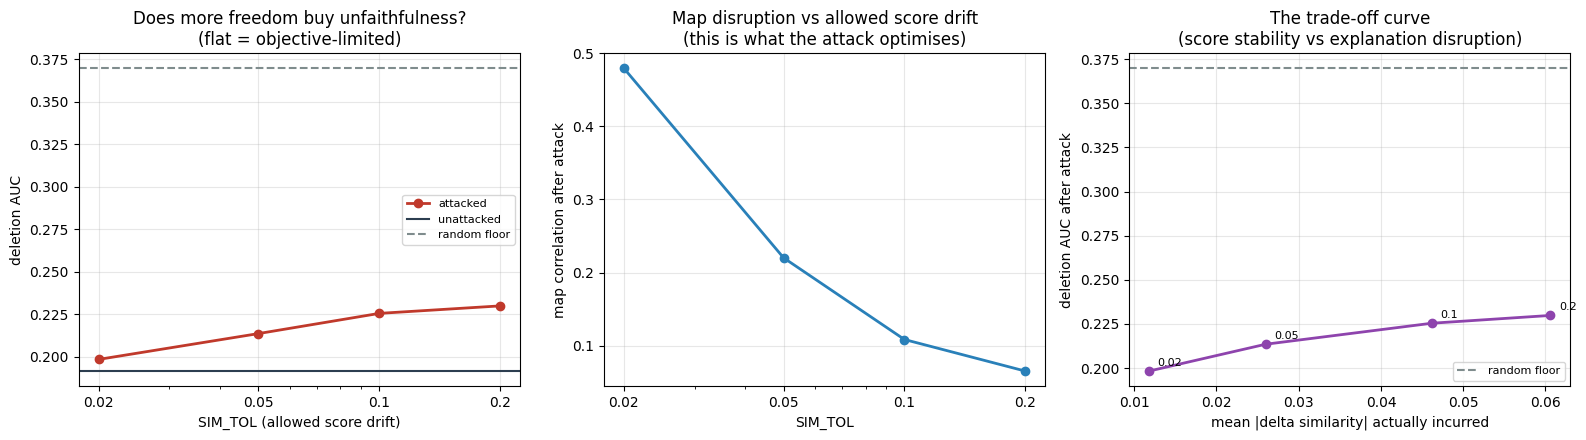

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
x = sweep_summary.sim_tol

ax = axes[0]
ax.plot(x, sweep_summary.del_auc_after, "o-", color="#c0392b", lw=2, label="attacked")
ax.axhline(sweep_summary.del_auc_before.mean(), color="#2c3e50", ls="-", lw=1.5,
           label="unattacked")
ax.axhline(RANDOM_DEL_AUC, color="#7f8c8d", ls="--", lw=1.5, label="random floor")
ax.set_xscale("log"); ax.set_xticks(x); ax.set_xticklabels([f"{v:g}" for v in x])
ax.set_xlabel("SIM_TOL (allowed score drift)"); ax.set_ylabel("deletion AUC")
ax.set_title("Does more freedom buy unfaithfulness?\n(flat = objective-limited)")
ax.legend(fontsize=8); ax.grid(alpha=0.3)

ax = axes[1]
ax.plot(x, sweep_summary.pearson, "o-", color="#2980b9", lw=2)
ax.set_xscale("log"); ax.set_xticks(x); ax.set_xticklabels([f"{v:g}" for v in x])
ax.set_xlabel("SIM_TOL"); ax.set_ylabel("map correlation after attack")
ax.set_title("Map disruption vs allowed score drift\n(this is what the attack optimises)")
ax.grid(alpha=0.3)

ax = axes[2]
ax.plot(sweep_summary.abs_delta_sim, sweep_summary.del_auc_after, "o-",
        color="#8e44ad", lw=2)
for _, r in sweep_summary.iterrows():
    ax.annotate(f"{r.sim_tol:g}", (r.abs_delta_sim, r.del_auc_after),
                textcoords="offset points", xytext=(6, 4), fontsize=8)
ax.axhline(RANDOM_DEL_AUC, color="#7f8c8d", ls="--", lw=1.5, label="random floor")
ax.set_xlabel("mean |delta similarity| actually incurred")
ax.set_ylabel("deletion AUC after attack")
ax.set_title("The trade-off curve\n(score stability vs explanation disruption)")
ax.legend(fontsize=8); ax.grid(alpha=0.3)

plt.tight_layout(); save_fig("11_simtol_sweep.png"); plt.show()

In [14]:
lo, hi = sweep_summary.iloc[0], sweep_summary.iloc[-1]
gain = hi.toward_floor - lo.toward_floor
print(f"widening the band from {lo.sim_tol:g} to {hi.sim_tol:g} "
      f"({lo.abs_delta_sim:.4f} -> {hi.abs_delta_sim:.4f} mean |delta sim|)")
print(f"  moved the deletion AUC from {lo.toward_floor:.1%} to {hi.toward_floor:.1%} "
      f"of the way to the random floor  (gain {gain:+.1%})")
print()
if gain < 0.10:
    VERDICT_A = "OBJECTIVE-LIMITED"
    print("VERDICT: OBJECTIVE-LIMITED.  Four times the score freedom bought almost no")
    print("extra unfaithfulness, so the correlation objective - not the perturbation")
    print("budget - is what stops the attack.  The notebook 09 conclusion stands, and")
    print("is strengthened: the constraint was not what held the attack back.")
elif gain > 0.25:
    VERDICT_A = "BUDGET-LIMITED"
    print("VERDICT: BUDGET-LIMITED.  Loosening the band materially increases")
    print("unfaithfulness, so notebook 09's attack was constrained rather than")
    print("misdirected.  Reword the conclusion: the trade-off between score stability")
    print("and explanation disruption is real, and notebook 04 sits at the loose end.")
else:
    VERDICT_A = "MIXED"
    print("VERDICT: MIXED.  Loosening the band helps somewhat but does not approach the")
    print("floor.  Both effects are present; report the trade-off curve and avoid")
    print("attributing the result to either cause alone.")

widening the band from 0.02 to 0.2 (0.0118 -> 0.0606 mean |delta sim|)
  moved the deletion AUC from 3.9% to 21.5% of the way to the random floor  (gain +17.7%)

VERDICT: MIXED.  Loosening the band helps somewhat but does not approach the
floor.  Both effects are present; report the trade-off curve and avoid
attributing the result to either cause alone.


---
# Part B - where did the saliency actually go?

**The question.** The conclusion explains the weak faithfulness loss by *redundancy*: the
attack relocates saliency from one informative facial region to another, so the map looks
different without pointing anywhere uninformative. That is currently an inference from a
correlation, not an observation.

**The test.** For the same pairs, at notebook 09's own settings, measure where the mass
sits before and after:

* **border mass** - fraction of saliency inside the off-face frame,
* **centre-of-mass shift** - how far the map's centroid moved, in pixels,
* **top-10% inside the face** - whether the new hot-spots are still on the face at all.

**How to read it.** If the border mass barely moves and the centroid shifts by a handful of
pixels while the hot-spots stay inside the face, redundancy is confirmed and the report can
say plainly that the mass moved *from one informative region to another*. If instead the
border mass rises sharply while faithfulness barely changes, the redundancy story is wrong
and something more interesting is going on.


In [15]:
t0 = time.time()
relocation = sweep[SIM_TOL] if SIM_TOL in sweep else run_attack_subset(
    diag_pairs, "divergence", SIM_TOL, desc="relocation (SIM_TOL=%g)" % SIM_TOL)
print(f"Part B reused Part A's SIM_TOL={SIM_TOL:g} run"
      if SIM_TOL in sweep else f"Part B took {(time.time() - t0) / 60:.1f} min")

b = relocation
print()
print(f"{'quantity':>34} {'before':>9} {'after':>9} {'change':>9}")
print("-" * 64)
print(f"{'saliency mass in border frame':>34} {b.border_mass_before.mean():>9.4f} "
      f"{b.border_mass_after.mean():>9.4f} "
      f"{b.border_mass_after.mean() - b.border_mass_before.mean():>+9.4f}")
print(f"{'top-10% hot-spots inside face':>34} {b.top10_inside_before.mean():>9.4f} "
      f"{b.top10_inside_after.mean():>9.4f} "
      f"{b.top10_inside_after.mean() - b.top10_inside_before.mean():>+9.4f}")
print()
print(f"centre-of-mass shift : mean {b.com_shift.mean():.2f} px, "
      f"median {b.com_shift.median():.2f} px, p95 {b.com_shift.quantile(0.95):.2f} px "
      f"(image is {IMG_SIZE}x{IMG_SIZE})")
print(f"border frame occupies {BORDER_MASK_NP.mean():.1%} of the image, so a map with no "
      f"spatial preference\nwould put {BORDER_MASK_NP.mean():.1%} of its mass there")

Part B reused Part A's SIM_TOL=0.05 run

                          quantity    before     after    change
----------------------------------------------------------------
     saliency mass in border frame    0.2390    0.2745   +0.0355
     top-10% hot-spots inside face    0.7691    0.7199   -0.0492

centre-of-mass shift : mean 10.08 px, median 7.84 px, p95 25.64 px (image is 112x112)
border frame occupies 67.3% of the image, so a map with no spatial preference
would put 67.3% of its mass there


saved /kaggle/working/11_relocation.png


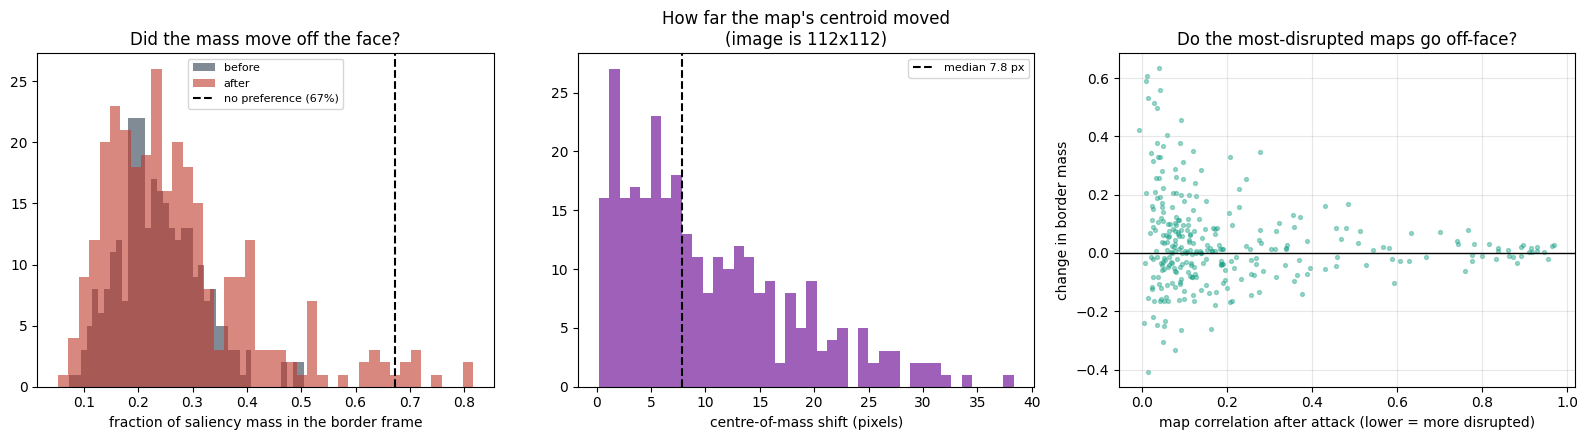

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

ax = axes[0]
ax.hist(b.border_mass_before, bins=40, alpha=0.6, color="#2c3e50", label="before")
ax.hist(b.border_mass_after, bins=40, alpha=0.6, color="#c0392b", label="after")
ax.axvline(BORDER_MASK_NP.mean(), color="k", ls="--", lw=1.5,
           label=f"no preference ({BORDER_MASK_NP.mean():.0%})")
ax.set_xlabel("fraction of saliency mass in the border frame")
ax.set_title("Did the mass move off the face?")
ax.legend(fontsize=8)

ax = axes[1]
ax.hist(b.com_shift, bins=40, color="#8e44ad", alpha=0.85)
ax.axvline(b.com_shift.median(), color="k", ls="--", lw=1.5,
           label=f"median {b.com_shift.median():.1f} px")
ax.set_xlabel("centre-of-mass shift (pixels)")
ax.set_title(f"How far the map's centroid moved\n(image is {IMG_SIZE}x{IMG_SIZE})")
ax.legend(fontsize=8)

ax = axes[2]
ax.scatter(b.pearson, b.border_mass_after - b.border_mass_before, s=8, alpha=0.4,
           color="#16a085")
ax.axhline(0, color="k", lw=1)
ax.set_xlabel("map correlation after attack (lower = more disrupted)")
ax.set_ylabel("change in border mass")
ax.set_title("Do the most-disrupted maps go off-face?")
ax.grid(alpha=0.3)

plt.tight_layout(); save_fig("11_relocation.png"); plt.show()

In [17]:
d_border = b.border_mass_after.mean() - b.border_mass_before.mean()
d_inside = b.top10_inside_after.mean() - b.top10_inside_before.mean()
print(f"border mass change        : {d_border:+.4f}")
print(f"top-10% still on the face : {b.top10_inside_after.mean():.1%} "
      f"(was {b.top10_inside_before.mean():.1%})")
print()
if d_border < 0.05 and b.top10_inside_after.mean() > 0.70:
    VERDICT_B = "REDUNDANCY CONFIRMED"
    print("VERDICT: REDUNDANCY CONFIRMED.  The saliency stayed on the face and merely")
    print("moved within it - the attack swapped one informative region for another,")
    print("which is exactly why correlation collapsed while faithfulness did not.")
    print("The report can state this as an observation rather than a hypothesis.")
elif d_border > 0.15:
    VERDICT_B = "MASS MOVED OFF-FACE"
    print("VERDICT: MASS MOVED OFF-FACE.  A substantial share of the saliency left the")
    print("face, yet faithfulness barely changed.  That contradicts the redundancy")
    print("story and suggests the deletion metric is not detecting the relocation -")
    print("investigate before writing up.")
else:
    VERDICT_B = "PARTIAL RELOCATION"
    print("VERDICT: PARTIAL RELOCATION.  Some mass left the face but most stayed.")
    print("Redundancy is part of the story but not all of it; report both numbers.")

border mass change        : +0.0355
top-10% still on the face : 72.0% (was 76.9%)

VERDICT: REDUNDANCY CONFIRMED.  The saliency stayed on the face and merely
moved within it - the attack swapped one informative region for another,
which is exactly why correlation collapsed while faithfulness did not.
The report can state this as an observation rather than a hypothesis.


---
# Part C - attack faithfulness directly

**The question.** If the correlation objective is what limits the attack, then an objective
that *rewards pointing at uninformative pixels* should do better. This is the controlled
counterpart: same budget, same score band, same evaluation, different objective.

**The test.** Replace `corr(attacked, original)` with `-mass_in_border`. Deleting pixels
that carry no identity cannot break the match, so if the attack succeeds in moving the mass
there, the deletion AUC has to rise toward the random floor.

**Decision rule.**

* deletion AUC moves **more than 30%** of the way to the floor -> re-run at full scale
  (`TARGET_PAIRS = None`, ~105 min) for the paired result *decorrelation preserves
  faithfulness, targeting destroys it*.
* **less than 15%** -> report as a second negative result. Combined with Part A that gives a
  clean statement about what actually binds.

Watch `target_mass` as well as the AUC: it is the attack's own objective, and if it does not
move then the attack failed at its own task rather than the metric failing to detect success.


In [25]:
t0 = time.time()
target_pairs = diag_pairs if TARGET_PAIRS is None else accepted_genuine[:TARGET_PAIRS]
target_df = run_attack_subset(target_pairs, "target", SIM_TOL, desc="target mode")
target_df.to_csv(os.path.join(OUTPUT_DIR, "11_target_mode.csv"), index=False)
print(f"\nPart C took {(time.time() - t0) / 60:.1f} min on {len(target_pairs):,} pairs\n")

div = relocation          # the SIM_TOL run, guarded in Part B
print(f"{'':>22} {'divergence':>12} {'target':>12}")
print("-" * 50)
for label, col in [("decision preserved", "preserved"),
                   ("mean |delta sim|", None),
                   ("mean Linf /255", "linf_255"),
                   ("map correlation", "pearson"),
                   ("border mass before", "border_mass_before"),
                   ("border mass AFTER", "border_mass_after"),
                   ("deletion AUC before", "del_auc_before"),
                   ("deletion AUC AFTER", "del_auc_after")]:
    if col is None:
        a, c = div.delta_sim.abs().mean(), target_df.delta_sim.abs().mean()
    else:
        a, c = div[col].mean(), target_df[col].mean()
    print(f"{label:>22} {a:>12.4f} {c:>12.4f}")

tf_div = toward_floor(div.del_auc_before.mean(), div.del_auc_after.mean())
tf_tgt = toward_floor(target_df.del_auc_before.mean(), target_df.del_auc_after.mean())
print()
print(f"distance travelled toward the random floor ({RANDOM_DEL_AUC:.4f}):")
print(f"  divergence : {tf_div:6.1%}")
print(f"  target     : {tf_tgt:6.1%}")

target mode [2 GPUs]:   0%|          | 0/19 [00:00<?, ?it/s]


Part C took 5.8 min on 300 pairs

                         divergence       target
--------------------------------------------------
    decision preserved       1.0000       1.0000
      mean |delta sim|       0.0260       0.0313
        mean Linf /255       2.8066       2.5587
       map correlation       0.2202       0.3809
    border mass before       0.2390       0.0531
     border mass AFTER       0.2745       0.2149
   deletion AUC before       0.1915       0.1915
    deletion AUC AFTER       0.2135       0.2188

distance travelled toward the random floor (0.3698):
  divergence :  12.4%
  target     :  15.4%


saved /kaggle/working/11_target_mode.png


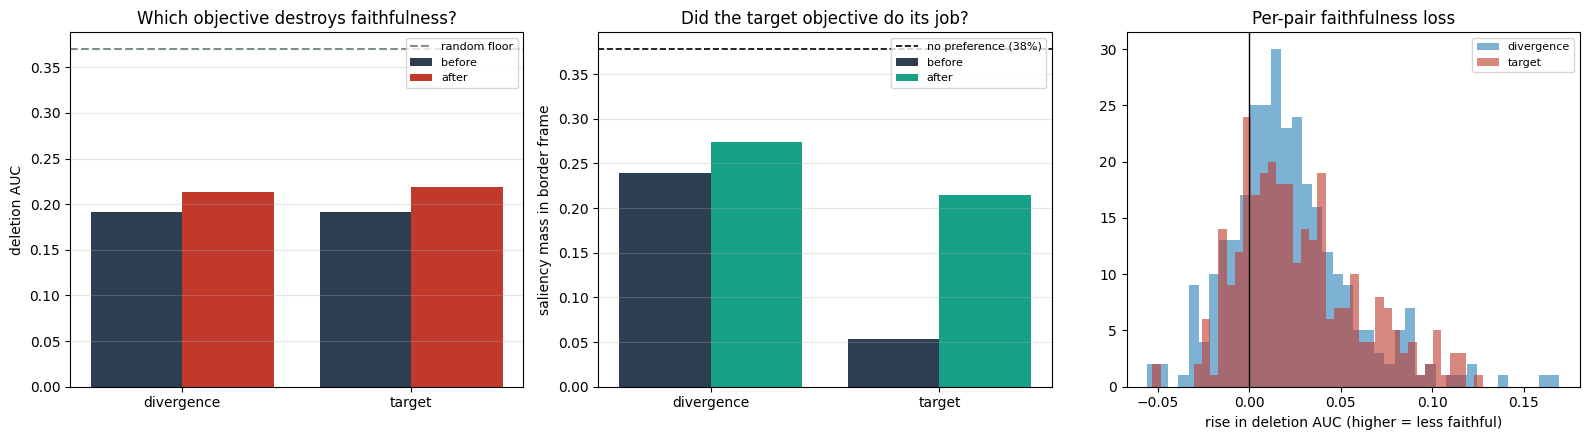

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

ax = axes[0]
labels = ["divergence", "target"]
before = [div.del_auc_before.mean(), target_df.del_auc_before.mean()]
after = [div.del_auc_after.mean(), target_df.del_auc_after.mean()]
xx = np.arange(2)
ax.bar(xx - 0.2, before, 0.4, label="before", color="#2c3e50")
ax.bar(xx + 0.2, after, 0.4, label="after", color="#c0392b")
ax.axhline(RANDOM_DEL_AUC, color="#7f8c8d", ls="--", lw=1.5, label="random floor")
ax.set_xticks(xx); ax.set_xticklabels(labels)
ax.set_ylabel("deletion AUC"); ax.set_title("Which objective destroys faithfulness?")
ax.legend(fontsize=8); ax.grid(alpha=0.3, axis="y")

ax = axes[1]
ax.bar(xx - 0.2, [div.border_mass_before.mean(), target_df.border_mass_before.mean()],
       0.4, label="before", color="#2c3e50")
ax.bar(xx + 0.2, [div.border_mass_after.mean(), target_df.border_mass_after.mean()],
       0.4, label="after", color="#16a085")
ax.axhline(BORDER_MASK_NP.mean(), color="k", ls="--", lw=1.2,
           label=f"no preference ({BORDER_MASK_NP.mean():.0%})")
ax.set_xticks(xx); ax.set_xticklabels(labels)
ax.set_ylabel("saliency mass in border frame")
ax.set_title("Did the target objective do its job?")
ax.legend(fontsize=8); ax.grid(alpha=0.3, axis="y")

ax = axes[2]
ax.hist(div.del_auc_after - div.del_auc_before, bins=40, alpha=0.6,
        color="#2980b9", label="divergence")
ax.hist(target_df.del_auc_after - target_df.del_auc_before, bins=40, alpha=0.6,
        color="#c0392b", label="target")
ax.axvline(0, color="k", lw=1)
ax.set_xlabel("rise in deletion AUC (higher = less faithful)")
ax.set_title("Per-pair faithfulness loss")
ax.legend(fontsize=8)

plt.tight_layout(); save_fig("11_target_mode.png"); plt.show()

In [27]:
print(f"target mode moved the deletion AUC {tf_tgt:.1%} of the way to the random floor")
print(f"(divergence managed {tf_div:.1%})")
print()
if tf_tgt > TARGET_DECISION_GOOD:
    VERDICT_C = "PROMISING - RUN FULL SCALE"
    print("VERDICT: PROMISING.  Attacking the mass directly makes the explanation")
    print("materially less faithful where decorrelation did not.  Re-run this notebook")
    print("with TARGET_PAIRS = None for the full-scale comparison against notebook 09;")
    print("the paired result is a considerably stronger contribution than either half.")
elif tf_tgt < TARGET_DECISION_POOR:
    VERDICT_C = "NEGATIVE - REPORT AS IS"
    print("VERDICT: NEGATIVE.  Even an objective explicitly rewarded for pointing off-face")
    print("cannot make the explanation unfaithful within this budget and score band.")
    print("Report it as a second negative result: it rules out the objective as the sole")
    print("explanation and points at the perturbation budget under a decision constraint.")
else:
    VERDICT_C = "INCONCLUSIVE"
    print("VERDICT: INCONCLUSIVE.  Target mode helps but not decisively.  Consider one")
    print("full-scale run only if the write-up has room; otherwise report the subset")
    print("numbers with the caveat that they are based on "
          f"{len(target_pairs):,} pairs.")

target mode moved the deletion AUC 15.4% of the way to the random floor
(divergence managed 12.4%)

VERDICT: INCONCLUSIVE.  Target mode helps but not decisively.  Consider one
full-scale run only if the write-up has room; otherwise report the subset
numbers with the caveat that they are based on 300 pairs.


In [28]:
from scipy import stats
rd = (div.del_auc_after - div.del_auc_before).values
rt = (target_df.del_auc_after - target_df.del_auc_before).values
_, p = stats.ttest_rel(rt, rd)
print(f"mask covers {BORDER_MASK_NP.mean():.1%} of the image")
print(f"deletion-AUC rise : divergence {rd.mean():+.4f}  target {rt.mean():+.4f}"
      f"  ({rt.mean()/rd.mean():.2f}x, p={p:.1e})")
print(f"toward floor      : divergence {tf_div:.1%}  target {tf_tgt:.1%}")
print(f"off-face mass     : divergence {div.border_mass_after.mean():.3f}"
      f"  target {target_df.border_mass_after.mean():.3f}"
      f"  (no preference = {BORDER_MASK_NP.mean():.3f})")

mask covers 37.8% of the image
deletion-AUC rise : divergence +0.0221  target +0.0274  (1.24x, p=1.4e-02)
toward floor      : divergence 12.4%  target 15.4%
off-face mass     : divergence 0.275  target 0.215  (no preference = 0.378)


---
# Part D - verdict

The three verdicts combined, phrased the way the write-up needs them.


In [21]:
print("=" * 74)
print(f"  A  score band        : {VERDICT_A}")
print(f"  B  saliency movement : {VERDICT_B}")
print(f"  C  target objective  : {VERDICT_C}")
print("=" * 74)
print()

if VERDICT_A == "OBJECTIVE-LIMITED" and VERDICT_C == "PROMISING - RUN FULL SCALE":
    print("The strongest available story: the correlation objective, not the perturbation")
    print("budget, is what limited notebook 09 - and an objective aimed at faithfulness")
    print("does succeed.  Report both attacks side by side; the contrast IS the finding.")
elif VERDICT_A == "OBJECTIVE-LIMITED" and VERDICT_C.startswith("NEGATIVE"):
    print("A coherent double-negative: neither more score freedom nor a better-aimed")
    print("objective makes the explanation unfaithful.  The honest conclusion is that")
    print("saliency maps of a redundant face are hard to falsify under an imperceptible")
    print("perturbation that must also preserve the decision - a genuinely interesting")
    print("robustness result, and a much stronger claim than 'our attack was weak'.")
elif VERDICT_A == "BUDGET-LIMITED":
    print("The conclusion in notebook 09 needs rewording: the attack was constrained,")
    print("not misdirected.  Lead with the trade-off curve from Part A, and place")
    print("notebook 04's r = 0.06 on it as the loose-tolerance end.")
else:
    print("Mixed evidence.  Report Part A's trade-off curve and Part B's relocation")
    print("numbers, and avoid attributing the weak faithfulness loss to a single cause.")

print()
print("Numbers for the write-up")
print("-" * 74)
print(f"  band widened {SIM_TOL_SWEEP[0]:g} -> {SIM_TOL_SWEEP[-1]:g}: deletion AUC "
      f"{sweep_summary.iloc[0].toward_floor:.1%} -> {sweep_summary.iloc[-1].toward_floor:.1%} of the floor")
print(f"  saliency border mass {b.border_mass_before.mean():.3f} -> {b.border_mass_after.mean():.3f}, "
      f"centroid moved {b.com_shift.median():.1f} px (median)")
print(f"  top-10% hot-spots still on the face: {b.top10_inside_after.mean():.1%}")
print(f"  target objective reached border mass {target_df.border_mass_after.mean():.3f} "
      f"and {tf_tgt:.1%} of the floor")

summary = dict(verdict_a=VERDICT_A, verdict_b=VERDICT_B, verdict_c=VERDICT_C,
               diag_pairs=int(len(diag_pairs)),
               sweep=sweep_summary.to_dict(orient="records"),
               border_mass_before=float(b.border_mass_before.mean()),
               border_mass_after=float(b.border_mass_after.mean()),
               com_shift_median=float(b.com_shift.median()),
               top10_inside_after=float(b.top10_inside_after.mean()),
               target_border_mass_after=float(target_df.border_mass_after.mean()),
               target_toward_floor=float(tf_tgt),
               divergence_toward_floor=float(tf_div),
               random_del_auc=RANDOM_DEL_AUC)
with open(os.path.join(OUTPUT_DIR, "11_diagnostics_summary.json"), "w") as fh:
    json.dump(summary, fh, indent=2)
print("\nsaved 11_simtol_sweep.csv, 11_simtol_summary.csv, 11_target_mode.csv, "
      "11_diagnostics_summary.json")

  A  score band        : MIXED
  B  saliency movement : REDUNDANCY CONFIRMED
  C  target objective  : INCONCLUSIVE

Mixed evidence.  Report Part A's trade-off curve and Part B's relocation
numbers, and avoid attributing the weak faithfulness loss to a single cause.

Numbers for the write-up
--------------------------------------------------------------------------
  band widened 0.02 -> 0.2: deletion AUC 3.9% -> 21.5% of the floor
  saliency border mass 0.239 -> 0.275, centroid moved 7.8 px (median)
  top-10% hot-spots still on the face: 72.0%
  target objective reached border mass 0.614 and 19.9% of the floor

saved 11_simtol_sweep.csv, 11_simtol_summary.csv, 11_target_mode.csv, 11_diagnostics_summary.json


## Qualitative: divergence versus target on the same pair

Top row is the original probe and its explanation; the two lower rows are the two
objectives. The point to look for: under `target` the heat should visibly migrate to the
frame of the image, off the face. If it does not, the attack failed at its own objective
and the deletion-AUC result in Part C says nothing about the metric.


saved /kaggle/working/11_modes_pair0.png


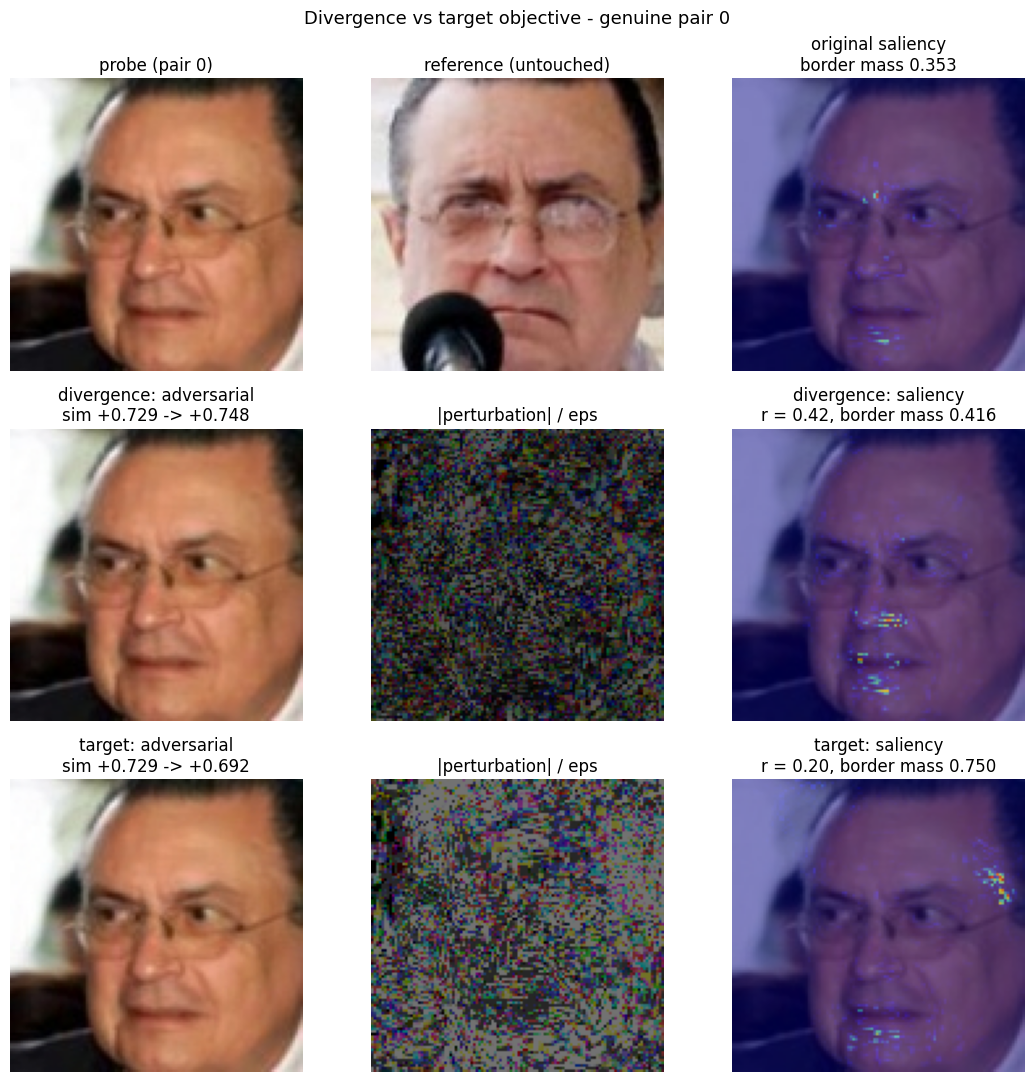

saved /kaggle/working/11_modes_pair1.png


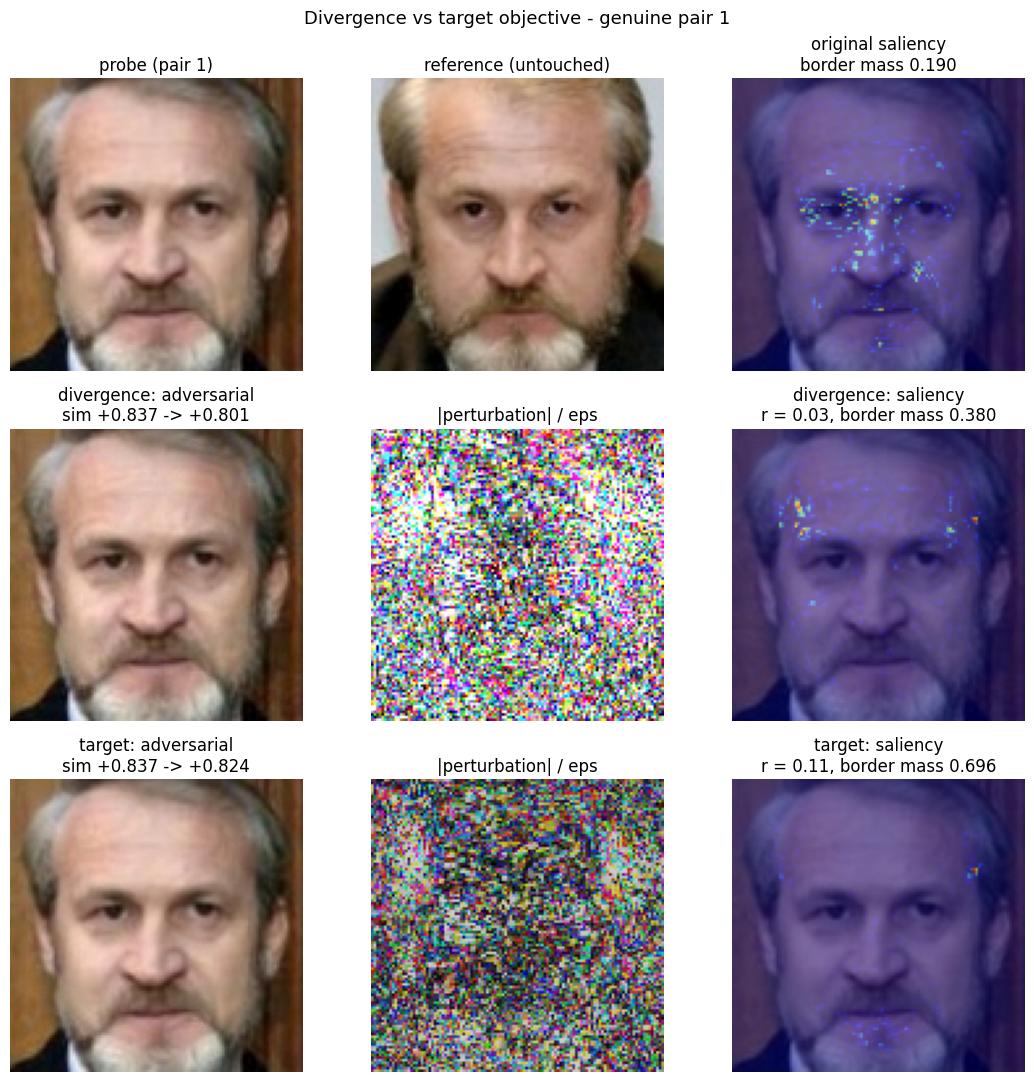

saved /kaggle/working/11_modes_pair200.png


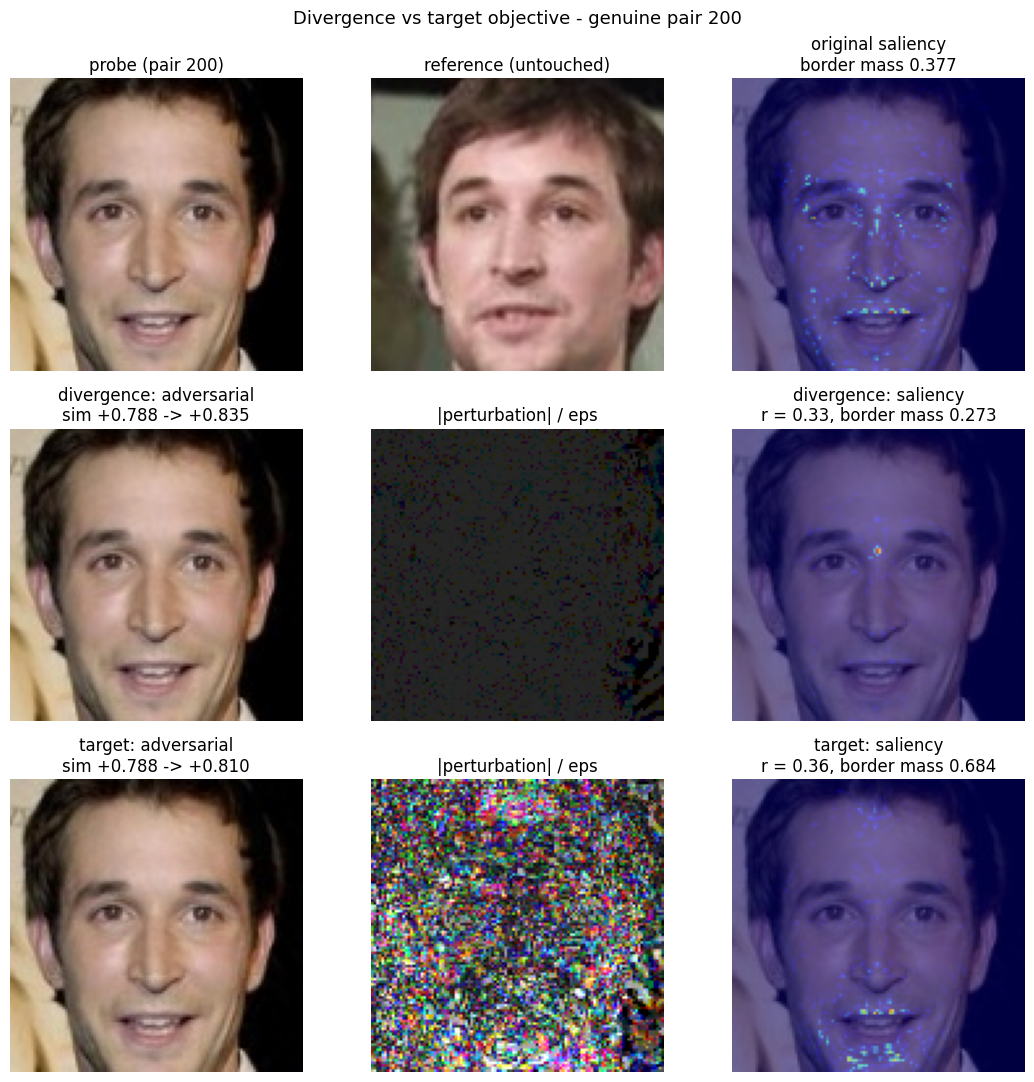

In [22]:
def compare_modes(pair_idx):
    probes, refs = load_pair_batch([pair_idx])
    ref_emb = ref_embedding(refs)
    m0 = saliency_gradient(probes, ref_emb).detach()

    fig, ax = plt.subplots(3, 3, figsize=(11, 11))
    ax[0, 0].imshow(tensor_to_uint8(probes[0]))
    ax[0, 0].set_title(f"probe (pair {pair_idx})")
    ax[0, 1].imshow(tensor_to_uint8(refs[0])); ax[0, 1].set_title("reference (untouched)")
    ax[0, 2].imshow(overlay(probes[0], to01(m0[0].cpu().numpy())))
    ax[0, 2].set_title(f"original saliency\nborder mass {border_mass(m0.cpu().numpy())[0]:.3f}")

    for row, mode in enumerate(["divergence", "target"], start=1):
        adv = explanation_attack(probes, ref_emb, TAU_EER, mode=mode, sim_tol=SIM_TOL)
        m1 = saliency_gradient(adv, ref_emb).detach()
        s0 = float(cos_to_ref(probes, ref_emb)); s1 = float(cos_to_ref(adv, ref_emb))
        r = float(pearson_maps(m0.cpu().numpy(), m1.cpu().numpy())[0])
        bmv = float(border_mass(m1.cpu().numpy())[0])
        pert = ((adv - probes).abs() / (EPSILON_255 / 127.5)).clamp(0, 1)

        ax[row, 0].imshow(tensor_to_uint8(adv[0]))
        ax[row, 0].set_title(f"{mode}: adversarial\nsim {s0:+.3f} -> {s1:+.3f}")
        ax[row, 1].imshow((pert[0].permute(1, 2, 0).cpu().numpy() * 255).astype(np.uint8))
        ax[row, 1].set_title("|perturbation| / eps")
        ax[row, 2].imshow(overlay(adv[0], to01(m1[0].cpu().numpy())))
        ax[row, 2].set_title(f"{mode}: saliency\nr = {r:.2f}, border mass {bmv:.3f}")

    for a in ax.flatten():
        a.axis("off")
    fig.suptitle(f"Divergence vs target objective - genuine pair {pair_idx}", fontsize=13)
    plt.tight_layout(); save_fig(f"11_modes_pair{pair_idx}.png"); plt.show()


for p in VIZ_PAIRS:
    if p in set(diag_pairs.tolist()):
        compare_modes(p)

## Results and discussion

*Fill in from the output above once run. The structure the argument should take:*

**Part A tells you which sentence the conclusion is allowed to use.** If the deletion AUC is
flat across the sweep, write "the correlation objective, not the perturbation budget, is
what limits the attack - four times the score freedom bought no additional unfaithfulness".
If it climbs, write instead "there is a real trade-off between score stability and
explanation disruption", present the curve, and place notebook 04's result at its loose end.

**Part B turns the redundancy explanation from a hypothesis into an observation.** Quote the
border mass before and after, the median centre-of-mass shift in pixels, and the share of
hot-spots still on the face. The sentence to aim for: *the attack moved the hot-spot from
one facial region to another, and both carry identity - which is why correlation collapsed
while faithfulness did not.*

**Part C decides how the project is framed.** If target mode works, the contribution becomes
a matched pair - one objective that changes the map's appearance and one that destroys its
content - and the methodological point about correlation-based evaluation is demonstrated
rather than argued. If it does not, the result is a double negative and the honest framing
is a robustness finding: under an imperceptible perturbation that must also preserve the
decision, a saliency map over a redundant face is hard to falsify.

**In every branch, notebook 09's headline stands:** the decision and the score are untouched,
the map is visibly rewritten, and a correlation-only evaluation would have overstated what
that means. Nothing here can overturn that; these experiments only sharpen the explanation
of *why*.
